<a href="https://colab.research.google.com/github/rahulsharma1208/MyProjects/blob/main/Jamboree_Education_Business_Case_Study_Rahul_Sharma_reviewed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Business Problem

Jamboree Education has created a feature which estimates the probability of a student getting admission into graduate schools abroad based on academic profile.

The objective is to:

* Understand factors affecting admission chances.
* Identify significant predictors.
* Build a regression model.
* Validate regression assumptions.
* Recommend improvements.

## Import Libraries

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from scipy import stats
from scipy.stats import shapiro

from statsmodels.compat import lzip
import statsmodels.stats.api as sms

## Load Dataset

In [2]:
!gdown 1u0YPIc6I5fVkdiCN0J540n_a05H_mvaV

Downloading...
From: https://drive.google.com/uc?id=1u0YPIc6I5fVkdiCN0J540n_a05H_mvaV
To: /content/Jamboree_Admission.csv
100% 16.2k/16.2k [00:00<00:00, 43.5MB/s]


In [3]:
df = pd.read_csv("Jamboree_Admission.csv")

In [4]:
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [ ]:
df.tail()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
495,496,332,108,5,4.5,4.0,9.02,1,0.87
496,497,337,117,5,5.0,5.0,9.87,1,0.96
497,498,330,120,5,4.5,5.0,9.56,1,0.93
498,499,312,103,4,4.0,5.0,8.43,0,0.73
499,500,327,113,4,4.5,4.5,9.04,0,0.84


## Basic Exploration

In [ ]:
print("Shape:", df.shape)

Shape: (500, 9)


**There are 500 datapoints and 9 features**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Serial No.         500 non-null    int64  
 1   GRE Score          500 non-null    int64  
 2   TOEFL Score        500 non-null    int64  
 3   University Rating  500 non-null    int64  
 4   SOP                500 non-null    float64
 5   LOR                500 non-null    float64
 6   CGPA               500 non-null    float64
 7   Research           500 non-null    int64  
 8   Chance of Admit    500 non-null    float64
dtypes: float64(4), int64(5)
memory usage: 35.3 KB


**All columns present in the dataset are numerical**

In [21]:
display(df.describe())

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
count,500.000000,500.000000,500.000000,500.000000,500.00000,500.000000,500.000000,500.00000
mean,316.472000,107.192000,3.114000,3.374000,3.48400,8.576440,0.560000,0.72174
std,11.295148,6.081868,1.143512,0.991004,0.92545,0.604813,0.496884,0.14114
min,290.000000,92.000000,1.000000,1.000000,1.00000,6.800000,0.000000,0.34000
25%,308.000000,103.000000,2.000000,2.500000,3.00000,8.127500,0.000000,0.63000
50%,317.000000,107.000000,3.000000,3.500000,3.50000,8.560000,1.000000,0.72000
75%,325.000000,112.000000,4.000000,4.000000,4.00000,9.040000,1.000000,0.82000
max,340.000000,120.000000,5.000000,5.000000,5.00000,9.920000,1.000000,0.97000


### Removing trailing spaces

In [5]:
print(df.columns.tolist()) # Before removal of trailing spaces

df.columns = df.columns.str.strip() # 'LOR ' / 'Chance of Admit ' had trailing spaces

print(df.columns.tolist()) # After removal of trailing spaces

['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR ', 'CGPA', 'Research', 'Chance of Admit ']
['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit']


### Dropping not predictive columns

In [6]:
df = df.drop(columns=['Serial No.'])
df.shape # Number of rows and columns after dropping

(500, 8)

## EDA

### Correlation Matrix of Target Variable with Other Features

In [7]:
correlation_matrix = df.corr(numeric_only=True)
print(correlation_matrix["Chance of Admit"].sort_values(ascending=False))

Chance of Admit      1.000000
CGPA                 0.882413
GRE Score            0.810351
TOEFL Score          0.792228
University Rating    0.690132
SOP                  0.684137
LOR                  0.645365
Research             0.545871
Name: Chance of Admit, dtype: float64


### Research vs Admission Probability

In [8]:
df.groupby("Research")["Chance of Admit"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
Research,,,,
0,220,0.634909,0.645,0.111918
1,280,0.789964,0.800,0.123208


### University Rating vs Admission Probability

In [9]:
df.groupby("University Rating")["Chance of Admit"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
University Rating,,,,
1,34,0.562059,0.57,0.099446
2,126,0.626111,0.64,0.107859
3,162,0.702901,0.72,0.098427
4,105,0.801619,0.82,0.117327
5,73,0.888082,0.91,0.074715


### Applicants divided into four admission-chance bands

In [10]:
df["Admission_Quartile"] = pd.qcut(df["Chance of Admit"], q=4, labels=["Q1: Lowest", "Q2", "Q3", "Q4"])

In [11]:
print(df.groupby("Admission_Quartile", observed=True)[
        [
            "GRE Score",
            "TOEFL Score",
            "University Rating",
            "SOP",
            "LOR",
            "CGPA",
            "Research",
            "Chance of Admit",
        ]
    ].mean().round(2)
)

                    GRE Score  TOEFL Score  University Rating   SOP   LOR  \
Admission_Quartile                                                          
Q1: Lowest             305.49       101.83               2.24  2.52  2.70   
Q2                     311.74       104.66               2.62  3.04  3.30   
Q3                     319.56       108.02               3.24  3.56  3.65   
Q4                     329.40       114.40               4.37  4.40  4.31   

                    CGPA  Research  Chance of Admit  
Admission_Quartile                                   
Q1: Lowest          7.93      0.24             0.54  
Q2                  8.35      0.35             0.68  
Q3                  8.71      0.71             0.77  
Q4                  9.33      0.95             0.90  


## Continuous vs Discrete Independent Variable

In [12]:
df_cont = ['GRE Score', 'TOEFL Score', 'CGPA']
df_disc = ['University Rating', 'SOP', 'LOR', 'Research']

## Univariate Analysis

### Target Variable

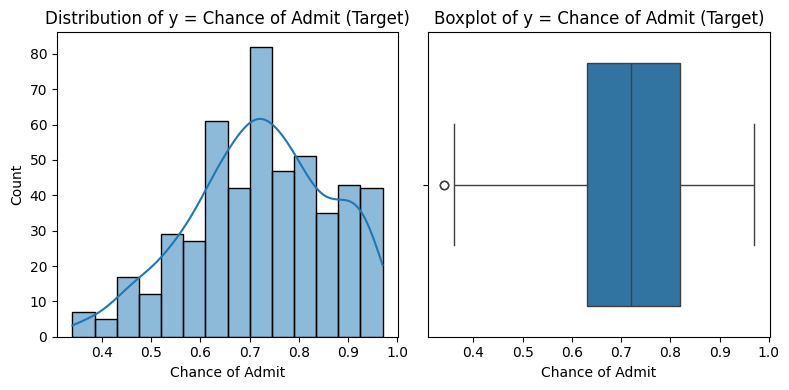

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
sns.histplot(x= df['Chance of Admit'], kde=True, ax=axes[0])
axes[0].set_title('Distribution of y = Chance of Admit (Target)')

sns.boxplot(x=df['Chance of Admit'], ax=axes[1])
axes[1].set_title('Boxplot of y = Chance of Admit (Target)')

plt.tight_layout()
plt.show()

In [ ]:
print("Target skew:", df['Chance of Admit'].skew())

Target skew: -0.289966210041158


**This shows that the target variable is slightly negatively skewed i.e. most values are relatively high. There is a small tail stretching toward lower admission chances. The distribution is fairly symmetric—only mildly left-skewed.**

### Independent Variables- Continuous

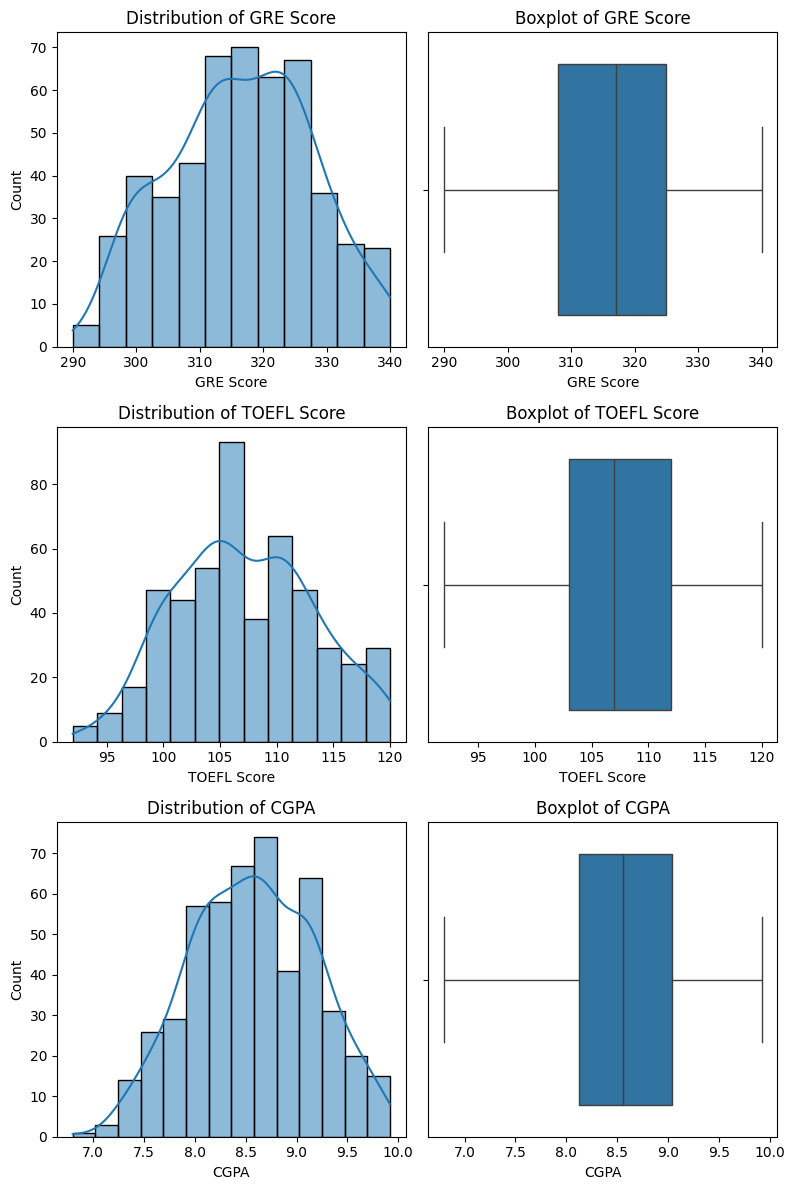

In [ ]:
fig, axes = plt.subplots(len(df_cont), 2, figsize=(8, 4 * len(df_cont)))
for i, col in enumerate(df_cont):
    sns.histplot(df[col], kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f'Distribution of {col}')
    sns.boxplot(x=df[col], ax=axes[i, 1])
    axes[i, 1].set_title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

In [ ]:
print("\ndf_cont skew:\n", df[df_cont].skew())


df_cont skew:
 GRE Score     -0.039842
TOEFL Score    0.095601
CGPA          -0.026613
dtype: float64


**GRE Score: essentially symmetric; a tiny left tail.**

**TOEFL Score: essentially symmetric; a tiny right tail.**

**CGPA: essentially symmetric; a tiny left tail.**

**All values are very close to zero, so these variables appear approximately normally distributed with no or very little skewness.**

### Independent Variables- Discrete

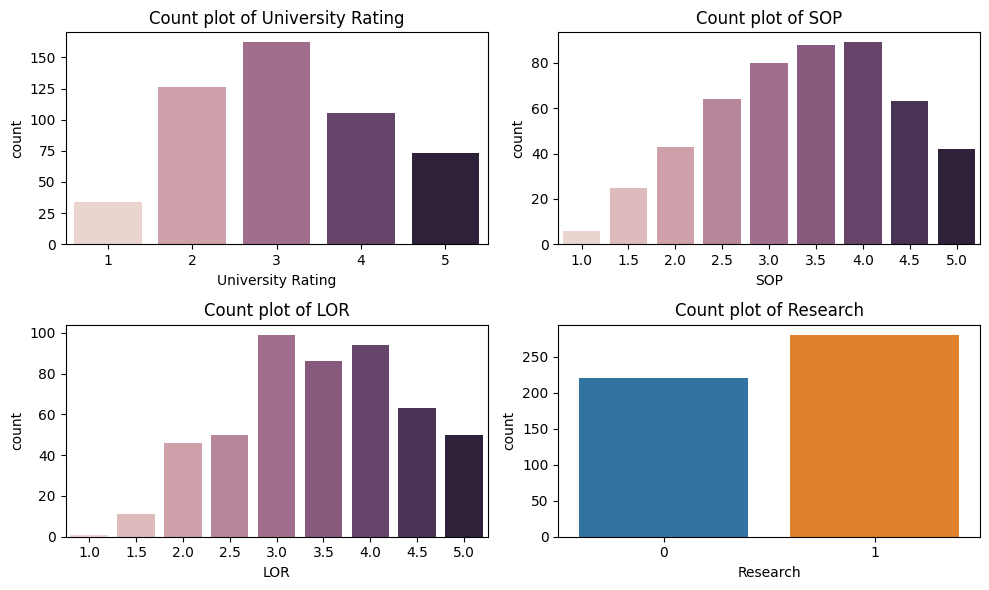

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, col in zip(axes.flatten(), df_disc):
    sns.countplot(x=df[col], ax=ax, hue=df[col], legend=False)
    ax.set_title(f'Count plot of {col}')

plt.tight_layout()
plt.show()

## Bivariate Analysis

#### Correlation

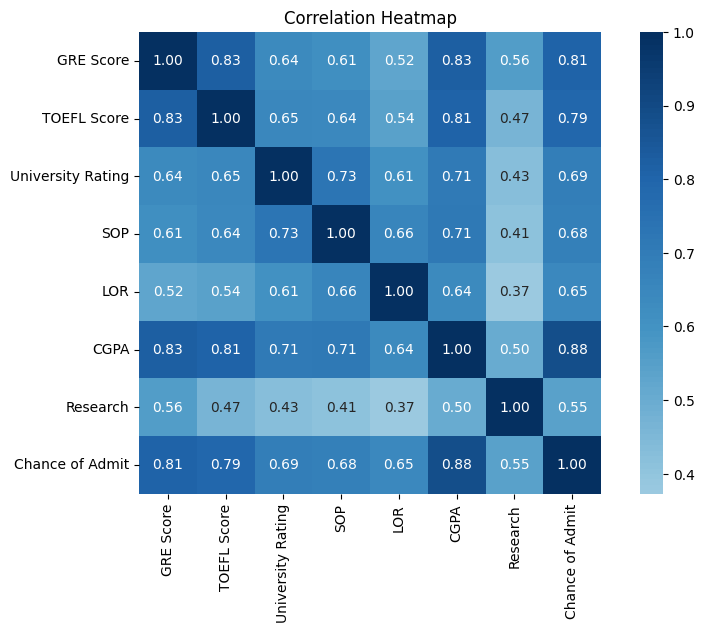

In [26]:
corr = df.select_dtypes(include=['int64', 'float64']).corr()
plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, fmt='.2f', center=0, square=True, cmap="RdBu")
plt.title('Correlation Heatmap')
plt.show()

In [15]:
print("\nCorrelation of Independent Variables with Target Variable:")
print(corr['Chance of Admit'].drop('Chance of Admit').sort_values(ascending=False))


Correlation of Independent Variables with Target Variable:
CGPA                 0.882413
GRE Score            0.810351
TOEFL Score          0.792228
University Rating    0.690132
SOP                  0.684137
LOR                  0.645365
Research             0.545871
Name: Chance of Admit, dtype: float64


**All are positive, so higher values tend to be associated with a higher admission chance:**
**CGPA — very strong positive association; strongest individual relationship.**

**GRE Score (0.810) and TOEFL Score (0.792) — strong positive associations.**

**University Rating, SOP, and LOR (~0.65–0.69) — moderately strong positive associations.**

**Research (0.546) — moderate positive association.**

### Continuous Independent variables vs Target Variable

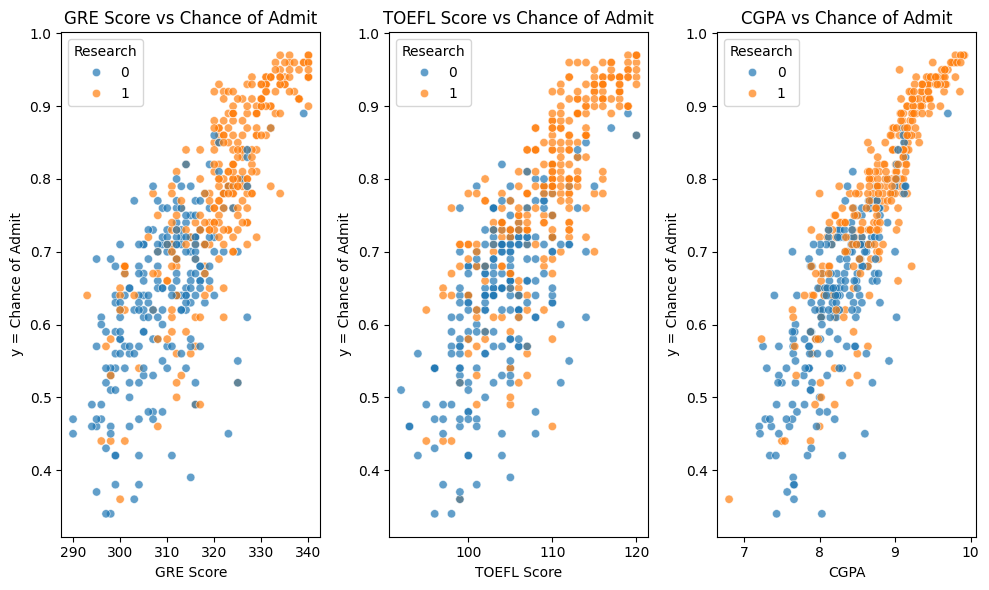

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(10, 6))
for ax, col in zip(axes, df_cont):
    sns.scatterplot(x=df[col], y=df['Chance of Admit'], hue=df['Research'], ax=ax, alpha=0.7)
    ax.set_xlabel(col)
    ax.set_ylabel('y = Chance of Admit')
    ax.set_title(f'{col} vs Chance of Admit')

plt.tight_layout()
plt.show()

###  Discrete Independent variables vs Target Variable

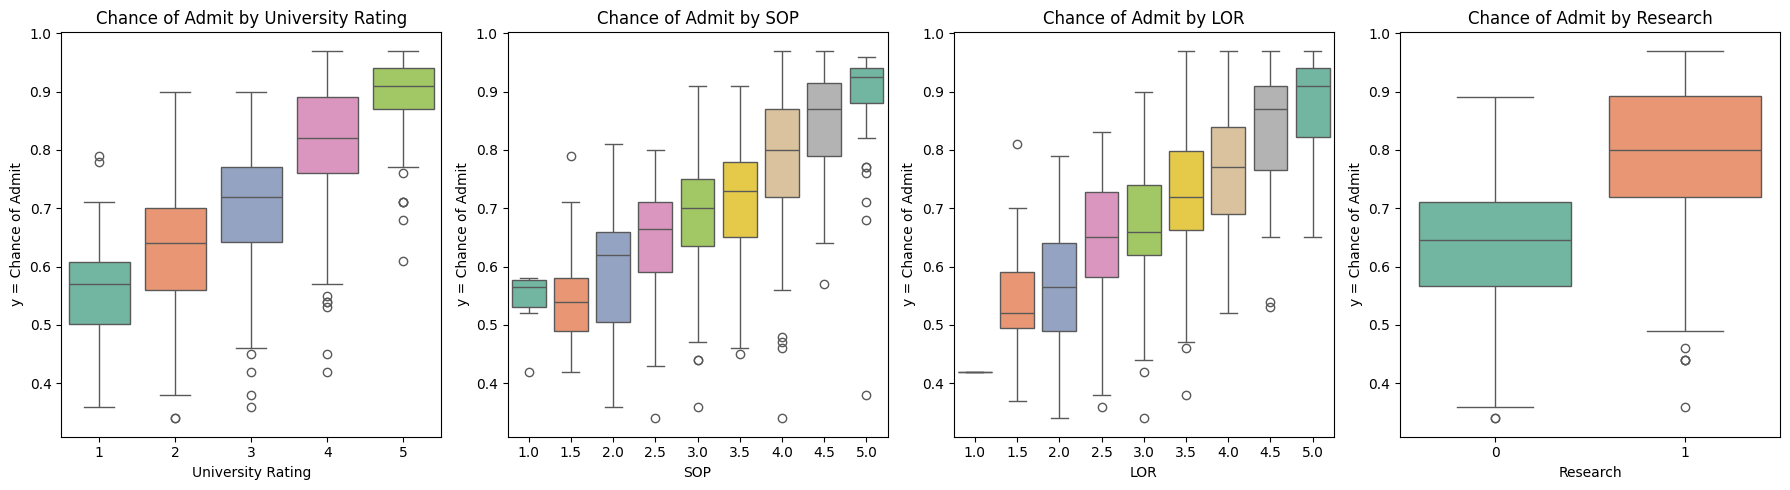

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, col in zip(axes, df_disc):
    sns.boxplot(x=df[col], y=df['Chance of Admit'], ax=ax, hue=df[col], legend=False, palette='Set2')
    ax.set_title(f'Chance of Admit by {col}')
    ax.set_ylabel('y = Chance of Admit')

plt.tight_layout()
plt.show()

## Data Preprocessing

### Outlier Detection

In [17]:
for label, series in [('Chance of Admit', df['Chance of Admit'])] + [(c, df[c]) for c in df_cont + df_disc]:
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((series < lower) | (series > upper)).sum()

    print(f"{label}: {n_out} outliers (bounds {lower:.2f}, {upper:.2f})")

Chance of Admit: 2 outliers (bounds 0.35, 1.10)
GRE Score: 0 outliers (bounds 282.50, 350.50)
TOEFL Score: 0 outliers (bounds 89.50, 125.50)
CGPA: 0 outliers (bounds 6.76, 10.41)
University Rating: 0 outliers (bounds -1.00, 7.00)
SOP: 0 outliers (bounds 0.25, 6.25)
LOR: 1 outliers (bounds 1.50, 5.50)
Research: 0 outliers (bounds -1.50, 2.50)


### Duplicate Check

In [18]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 0


**The dataset does not have any duplicate values.**

### Missing Values

In [ ]:
print("\nMissing values:\n", df.isnull().sum())


Missing values:
 GRE Score             0
TOEFL Score           0
University Rating     0
SOP                   0
LOR                   0
CGPA                  0
Research              0
Chance of Admit       0
Admission_Quartile    0
dtype: int64


**The data does not have any missing values.**

## Bifurcating target and independent variables

In [19]:
y = df['Chance of Admit'] # Target or dependent variable
y.head()

,Chance of Admit
0,0.92
1,0.76
2,0.72
3,0.80
4,0.65


In [20]:
X = df.drop(columns=['Chance of Admit', 'Admission_Quartile']) # Independent variables
X.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
0,337,118,4,4.5,4.5,9.65,1
1,324,107,4,4.0,4.5,8.87,1
2,316,104,3,3.0,3.5,8.00,1
3,322,110,3,3.5,2.5,8.67,1
4,314,103,2,2.0,3.0,8.21,0


## Model Building

### Linear Regression Using Scikit-Learn

#### Splitting the Data into train and test datasets

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("\nTrain:", X_train.shape, " Test:", X_test.shape)


Train: (400, 7)  Test: (100, 7)


In [44]:
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

LinearRegression()

In [48]:
train_pred_lr = model_lr.predict(X_train)
test_pred_lr = model_lr.predict(X_test)

#### Model coefficients

In [49]:
coef_df = pd.concat([
    pd.DataFrame({"Feature": ["Intercept"], "Coefficient": [model_lr.intercept_]}),
    pd.DataFrame({"Feature": X_train.columns, "Coefficient": model_lr.coef_})
], ignore_index=True)

coef_df

,Feature,Coefficient
0,Intercept,-1.421447
1,GRE Score,0.002434
2,TOEFL Score,0.002996
3,University Rating,0.002569
4,SOP,0.001814
5,LOR,0.017238
6,CGPA,0.112527
7,Research,0.024027


In [54]:
print("Train Score:", model_lr.score(X_train, y_train))
print("Test Score:", model_lr.score(X_test, y_test))

Train Score: 0.8210671369321553
Test Score: 0.8188432567829631


In [55]:
def adjusted_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def manual_metrics(y_true, y_pred, p):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    residuals = y_true - y_pred
    mae = np.mean(np.abs(residuals))
    rmse = np.sqrt(np.mean(residuals ** 2))
    r2 = 1 - np.sum(residuals ** 2) / np.sum((y_true - y_true.mean()) ** 2)
    return {'MAE': mae, 'RMSE': rmse, 'R²': r2, 'Adjusted R²': adjusted_r2(r2, len(y_true), p)}

def library_metrics(y_true, y_pred, p):
    r2 = r2_score(y_true, y_pred)
    return {'MAE': mean_absolute_error(y_true, y_pred), 'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)), 'R²': r2, 'Adjusted R²': adjusted_r2(r2, len(y_true), p)}

def evaluation_table(y_train, train_pred, y_test, test_pred, p):
    rows = []
    for data, y_true, y_pred in [('Train', y_train, train_pred), ('Test', y_test, test_pred)]:
        for method, function in [('Manual formula', manual_metrics), ('Library', library_metrics)]:
            rows.append({'Data': data, 'Method': method, **function(y_true, y_pred, p)})
    return pd.DataFrame(rows).round(4)

In [56]:
eval_sklearn_lr = evaluation_table(y_train, train_pred_lr, y_test, test_pred_lr, X_train.shape[1])
eval_sklearn_lr

,Data,Method,MAE,RMSE,R²,Adjusted R²
0,Train,Manual formula,0.0425,0.0594,0.8211,0.8179
1,Train,Library,0.0425,0.0594,0.8211,0.8179
2,Test,Manual formula,0.0427,0.0609,0.8188,0.8051
3,Test,Library,0.0427,0.0609,0.8188,0.8051


### Linear Regression Using Statsmodel

In [57]:
X_train_sm = sm.add_constant(X_train)
X_test_sm = sm.add_constant(X_test)

In [58]:
model_sm = sm.OLS(y_train, X_train_sm).fit()
print(model_sm.summary())

                            OLS Regression Results                            
Dep. Variable:        Chance of Admit   R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     257.0
Date:                Sat, 18 Jul 2026   Prob (F-statistic):          3.41e-142
Time:                        05:52:42   Log-Likelihood:                 561.91
No. Observations:                 400   AIC:                            -1108.
Df Residuals:                     392   BIC:                            -1076.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -1.4214      0.12

#### Model Evaluation using library

In [59]:
train_pred_sm = model_sm.predict(X_train_sm)
test_pred_sm = model_sm.predict(X_test_sm)

print('Test MAE :', mean_absolute_error(y_test, test_pred_sm))
print('Test RMSE:', np.sqrt(mean_squared_error(y_test, test_pred_sm)))
print('Test R²  :', r2_score(y_test, test_pred_sm))

Test MAE : 0.04272265427705371
Test RMSE: 0.06086588041578314
Test R²  : 0.8188432567829627


#### Model Evaluation using code from scratch

In [60]:
train_pred = train_pred_sm
test_pred = test_pred_sm

In [61]:
eval_statsmodels_lr = evaluation_table(y_train, train_pred_sm, y_test, test_pred_sm, X_train.shape[1])
eval_statsmodels_lr

,Data,Method,MAE,RMSE,R²,Adjusted R²
0,Train,Manual formula,0.0425,0.0594,0.8211,0.8179
1,Train,Library,0.0425,0.0594,0.8211,0.8179
2,Test,Manual formula,0.0427,0.0609,0.8188,0.8051
3,Test,Library,0.0427,0.0609,0.8188,0.8051


#### VIF Calculation

In [62]:
# Manual VIF through sklearn
def vif_with_sklearn(X):
    rows = []
    for feature in X.columns:
        X_others = X.drop(columns=feature)
        aux_model = LinearRegression().fit(X_others, X[feature])
        aux_r2 = aux_model.score(X_others, X[feature])
        vif = np.inf if np.isclose(aux_r2, 1.0) else 1 / (1 - aux_r2)
        rows.append({'Feature': feature, 'VIF': vif})
    return pd.DataFrame(rows).sort_values('VIF', ascending=False).reset_index(drop=True)

vif_sklearn = vif_with_sklearn(X_train)
vif_sklearn

,Feature,VIF
0,CGPA,4.654540
1,GRE Score,4.489983
2,TOEFL Score,3.664298
3,SOP,2.785764
4,University Rating,2.572110
5,LOR,1.977698
6,Research,1.518065


In [63]:
X_vif_sm = sm.add_constant(X_train, has_constant='add')
vif_statsmodels = pd.DataFrame({'Feature': X_vif_sm.columns, 'VIF': [variance_inflation_factor(X_vif_sm.values, i) for i in range(X_vif_sm.shape[1])]})
vif_statsmodels = vif_statsmodels.query("Feature != 'const'").sort_values('VIF', ascending=False).reset_index(drop=True)
vif_statsmodels

,Feature,VIF
0,CGPA,4.654540
1,GRE Score,4.489983
2,TOEFL Score,3.664298
3,SOP,2.785764
4,University Rating,2.572110
5,LOR,1.977698
6,Research,1.518065


##### Remove variables with VIF > 5

In [64]:
X_train_vif = X_train.copy()
X_test_vif = X_test.copy()

while True:
    X_vif_temp = sm.add_constant(X_train_vif, has_constant='add')
    vif = pd.DataFrame({'Feature': X_vif_temp.columns, 'VIF': [variance_inflation_factor(X_vif_temp.values, i) for i in range(X_vif_temp.shape[1])]})
    vif_predictors = vif.query("Feature != 'const'")
    if vif_predictors['VIF'].max() <= 5:
        break
    remove_feature = vif_predictors.sort_values('VIF', ascending=False).iloc[0]['Feature']
    print('Dropping:', remove_feature)
    X_train_vif = X_train_vif.drop(columns=remove_feature)
    X_test_vif = X_test_vif.drop(columns=remove_feature)

vif_predictors.sort_values('VIF', ascending=False).reset_index(drop=True)

,Feature,VIF
0,CGPA,4.654540
1,GRE Score,4.489983
2,TOEFL Score,3.664298
3,SOP,2.785764
4,University Rating,2.572110
5,LOR,1.977698
6,Research,1.518065


#### Rebuilding model after VIF removal

In [65]:
X_train_sm2 = sm.add_constant(X_train_vif, has_constant='add')
X_test_sm2 = sm.add_constant(X_test_vif, has_constant='add')
model2 = sm.OLS(y_train, X_train_sm2).fit()
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:        Chance of Admit   R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     257.0
Date:                Sat, 18 Jul 2026   Prob (F-statistic):          3.41e-142
Time:                        05:55:16   Log-Likelihood:                 561.91
No. Observations:                 400   AIC:                            -1108.
Df Residuals:                     392   BIC:                            -1076.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -1.4214      0.12

#### Evaluate new model

In [66]:
train_pred2 = model2.predict(X_train_sm2)
test_pred2 = model2.predict(X_test_sm2)
eval_statsmodels_vif = evaluation_table(y_train, train_pred2, y_test, test_pred2, X_train_vif.shape[1])
eval_statsmodels_vif

,Data,Method,MAE,RMSE,R²,Adjusted R²
0,Train,Manual formula,0.0425,0.0594,0.8211,0.8179
1,Train,Library,0.0425,0.0594,0.8211,0.8179
2,Test,Manual formula,0.0427,0.0609,0.8188,0.8051
3,Test,Library,0.0427,0.0609,0.8188,0.8051


#### Residuals

In [67]:
errors = y_train - train_pred2

In [68]:
res = stats.shapiro(errors)
res.statistic

np.float64(0.9291008662710203)

#### Mean of Residuals

In [69]:
print("Mean residual =", errors.mean())

Mean residual = 3.920475055707584e-16


#### Residual Plot (Linearity)

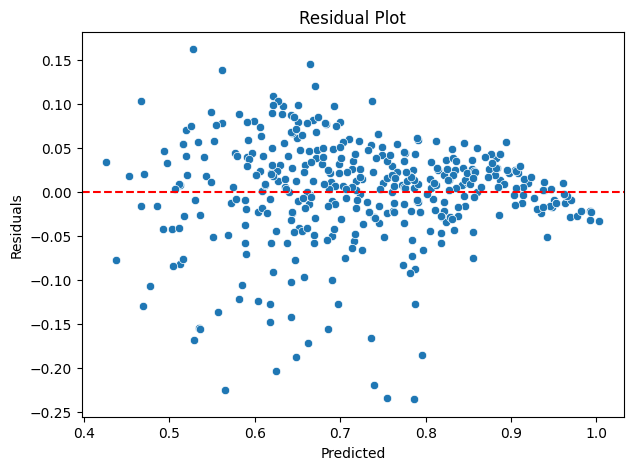

In [70]:
plt.figure(figsize=(7,5))

sns.scatterplot(x=train_pred2, y=errors)

plt.axhline(0, color='red', linestyle='--')

plt.xlabel("Predicted")

plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.show()

#### Homoscedasticity

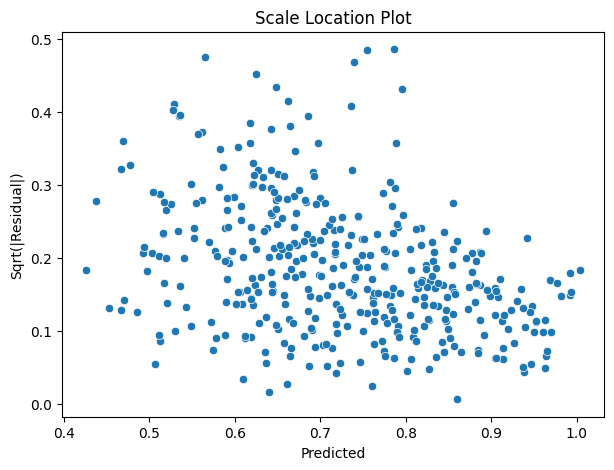

In [71]:
plt.figure(figsize=(7,5))

sns.scatterplot(x=train_pred2, y=np.sqrt(np.abs(errors)))

plt.xlabel("Predicted")

plt.ylabel("Sqrt(|Residual|)")

plt.title("Scale Location Plot")

plt.show()

In [72]:
name = ['F statistic', 'p-value', 'alternative']
test = sms.het_goldfeldquandt(y_train, X_train_sm2)
lzip(name, test)

[('F statistic', np.float64(0.9506884043302326)),
 ('p-value', np.float64(0.6367845922443005)),
 ('alternative', 'increasing')]

#### Distribution of Residuals

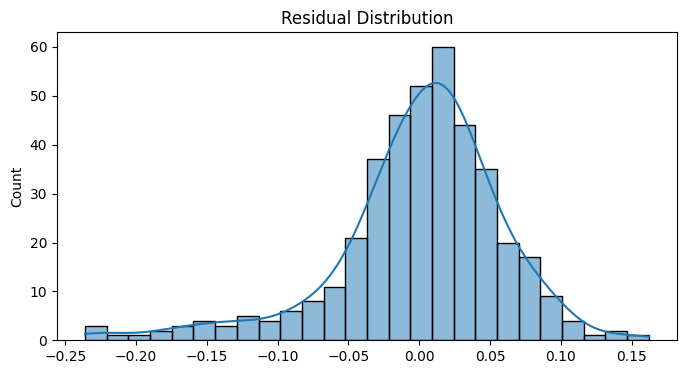

In [73]:
plt.figure(figsize=(8, 4))

sns.histplot(errors, kde=True)

plt.title("Residual Distribution")

plt.show()

#### QQ Plot

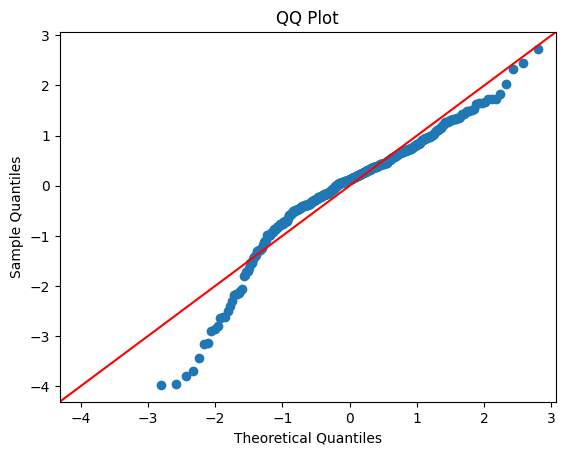

In [74]:
sm.qqplot(errors, line='45', fit=True)

plt.title("QQ Plot")

plt.show()

### L2 Regularization — Ridge Regression

In [75]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [76]:
ridge = Ridge(alpha=1)
ridge.fit(X_train_scaled, y_train)

Ridge(alpha=1)

In [77]:
ridge_train = ridge.predict(X_train_scaled)
ridge_test = ridge.predict(X_test_scaled)

In [78]:
eval_ridge = evaluation_table(y_train, ridge_train, y_test, ridge_test, X_train.shape[1])
eval_ridge

,Data,Method,MAE,RMSE,R²,Adjusted R²
0,Train,Manual formula,0.0425,0.0594,0.8211,0.8179
1,Train,Library,0.0425,0.0594,0.8211,0.8179
2,Test,Manual formula,0.0427,0.0609,0.8188,0.8050
3,Test,Library,0.0427,0.0609,0.8188,0.8050


### L1 Regularization — Lasso Regression

In [79]:
lasso = Lasso(alpha=0.001, max_iter=10000)

In [80]:
lasso.fit(X_train_scaled, y_train)

Lasso(alpha=0.001, max_iter=10000)

In [81]:
lasso_train = lasso.predict(X_train_scaled)
lasso_test = lasso.predict(X_test_scaled)

In [82]:
eval_lasso = evaluation_table(y_train, lasso_train, y_test, lasso_test, X_train.shape[1])
eval_lasso

,Data,Method,MAE,RMSE,R²,Adjusted R²
0,Train,Manual formula,0.0425,0.0594,0.8210,0.8178
1,Train,Library,0.0425,0.0594,0.8210,0.8178
2,Test,Manual formula,0.0425,0.0608,0.8192,0.8054
3,Test,Library,0.0425,0.0608,0.8192,0.8054


## Comparing all models

In [83]:
comparison_rows = []
models_for_comparison = [
    ('Linear Regression (sklearn)', train_pred_lr, test_pred_lr, X_train.shape[1]),
    ('Linear Regression (statsmodels)', train_pred_sm, test_pred_sm, X_train.shape[1]),
    ('OLS after VIF removal', train_pred2, test_pred2, X_train_vif.shape[1]),
    ('Ridge (L2)', ridge_train, ridge_test, X_train.shape[1]),
    ('Lasso (L1)', lasso_train, lasso_test, X_train.shape[1]),
]
for model_name, train_predictions, test_predictions, p in models_for_comparison:
    train_scores = library_metrics(y_train, train_predictions, p)
    test_scores = library_metrics(y_test, test_predictions, p)
    comparison_rows.append({'Model': model_name, 'Train R²': train_scores['R²'], 'Test R²': test_scores['R²'], 'Test Adjusted R²': test_scores['Adjusted R²'], 'Test MAE': test_scores['MAE'], 'Test RMSE': test_scores['RMSE']})
comparison = pd.DataFrame(comparison_rows).round(4)
comparison

,Model,Train R²,Test R²,Test Adjusted R²,Test MAE,Test RMSE
0,Linear Regression (sklearn),0.8211,0.8188,0.8051,0.0427,0.0609
1,Linear Regression (statsmodels),0.8211,0.8188,0.8051,0.0427,0.0609
2,OLS after VIF removal,0.8211,0.8188,0.8051,0.0427,0.0609
3,Ridge (L2),0.8211,0.8188,0.8050,0.0427,0.0609
4,Lasso (L1),0.8210,0.8192,0.8054,0.0425,0.0608


## Actionable Insights & Recommendations

1. CGPA is typically the strongest positive predictor of admission probability.
2. GRE Score and TOEFL Score also contribute significantly to the prediction.
3. Students with Research Experience generally have a higher chance of admission than those without.
4. University Rating, SOP, and LOR may become statistically insignificant after controlling for CGPA, GRE, and TOEFL due to shared information.
5. VIF analysis helps identify multicollinearity; removing variables with high VIF improves coefficient stability without substantially affecting predictive performance.
6. The residual mean should be approximately zero, supporting an unbiased model.
7. A random residual plot and a nearly constant spread indicate that the assumptions of linearity and homoscedasticity are reasonably satisfied.
8. A bell-shaped residual distribution and QQ plot points close to the reference line indicate that residuals are approximately normally distributed.
9. Compare Linear Regression, Ridge, and Lasso. If their test R² values are similar, the simpler linear regression model is generally preferred for its interpretability. If multicollinearity is present, Ridge often provides more stable coefficients.